In [8]:
from pathlib import Path

import cmocean as cm
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as signal

import pinner2026_jpo_code
import pinner2026_jpo_code.spectra
import pinner2026_jpo_code.constants

RAW_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "raw"
INTERIM_DATA_DIR: Path = pinner2026_jpo_code.DATA_DIR / "interim"

In [9]:
u = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_u.csv", parse_dates=True, index_col=0)
u.columns = u.columns.astype(float)
v = pd.read_csv(INTERIM_DATA_DIR / "AWI207_bottom_v.csv", parse_dates=True, index_col=0)
v.columns = v.columns.astype(float)

In [10]:
u.columns

Index([ 30.23,  38.23,  46.23,  54.23,  62.23,  70.23,  78.23,  86.23,  94.23,
       102.23, 110.23, 118.23, 126.23, 134.23, 142.23, 150.23, 158.23, 166.23,
       174.23, 182.23, 190.23],
      dtype='float64')

# Filter to just inertial frequencies

In [57]:
f = pinner2026_jpo_code.constants.get_coriolis_frequency(lat=-64, unit="cpd", absolute=True)
print(f"{f = :.3}")

f = 1.8


In [49]:
def filter_to_f(col, low_cut=0.96 * f, high_cut=1.06 * f):
    low_cut_Hz = 1 / (24 / low_cut * 60 * 60)  # in Hz, default 1.7 cpd
    high_cut_Hz = 1 / (24 / high_cut * 60 * 60)  # in Hz, default: 1.91 cpd

    fs = 1 / (1 * 60 * 60)  # in Hz, one measurement every hour
    order = 40
    sos = signal.butter(
        N=order, Wn=(low_cut_Hz, high_cut_Hz), btype="bandpass", fs=fs, output="sos"
    )
    filtered = signal.sosfiltfilt(sos, col.to_numpy())
    return pd.Series(filtered, index=col.index)


# def filter_to_f(col):
#     fs = 1 / (1 * 60 * 60)
#     low_cut = 1 / (13.8 * 60 * 60)
#     high_cut = 1 / (12.5 * 60 * 60)
#     order = 40
#     sos = signal.butter(N=order, Wn=(low_cut, high_cut), btype="bandpass", fs=fs, output="sos")
#     filtered = signal.sosfiltfilt(sos, col.to_numpy())
#     return pd.Series(filtered, index=col.index)

u_f = u.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_f, axis="index")
v_f = v.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_f, axis="index")

(0.01, 0.07)

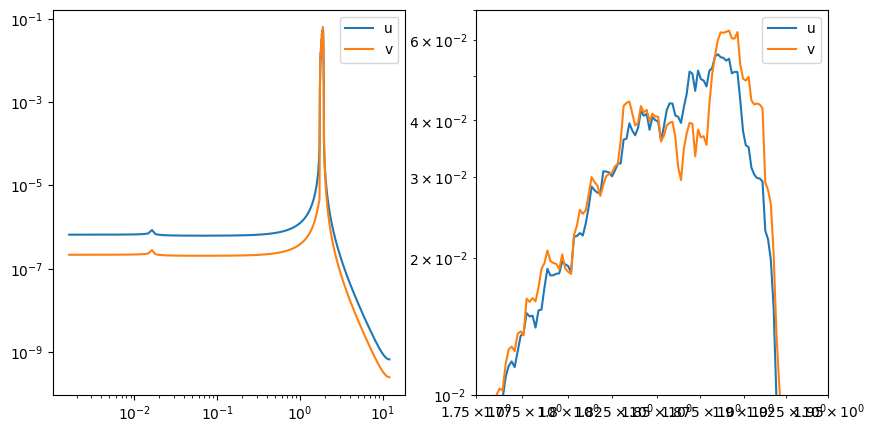

In [13]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 10

mab = 54.23
u_freq, u_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_f.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
v_freq, v_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    v_f.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
ax[0].loglog(u_freq, u_spectrum, label="u")
ax[0].loglog(v_freq, v_spectrum, label="v")
ax[0].legend()
# ax[0].set_xlim(1.7, 16)
# ax[0].set_ylim(9e-4, 0.2)

ax[1].loglog(u_freq, u_spectrum, label="u")
ax[1].loglog(v_freq, v_spectrum, label="v")
ax[1].legend()
ax[1].set_xlim(1.75, 1.95)
ax[1].set_ylim(1e-2, 7e-2)

In [14]:
inertial_wind = pd.read_csv(INTERIM_DATA_DIR / "inertial_wind_2022_2023.csv")
inertial_wind = inertial_wind.set_index(pd.to_datetime(inertial_wind["Unnamed: 0"]))
inertial_wind = inertial_wind.drop("Unnamed: 0", axis="columns")
for _i, col in enumerate(inertial_wind.columns):
    inertial_wind[col] = inertial_wind[col].str.replace("i", "j").apply(lambda x: complex(x))

# select mooring C and cut down to the length of the mesurement data
inertial_wind_at_C = inertial_wind["C"].loc[u_f.index[0] : u_f.index[-1]]
# inertial_wind_at_C = inertial_wind_at_C

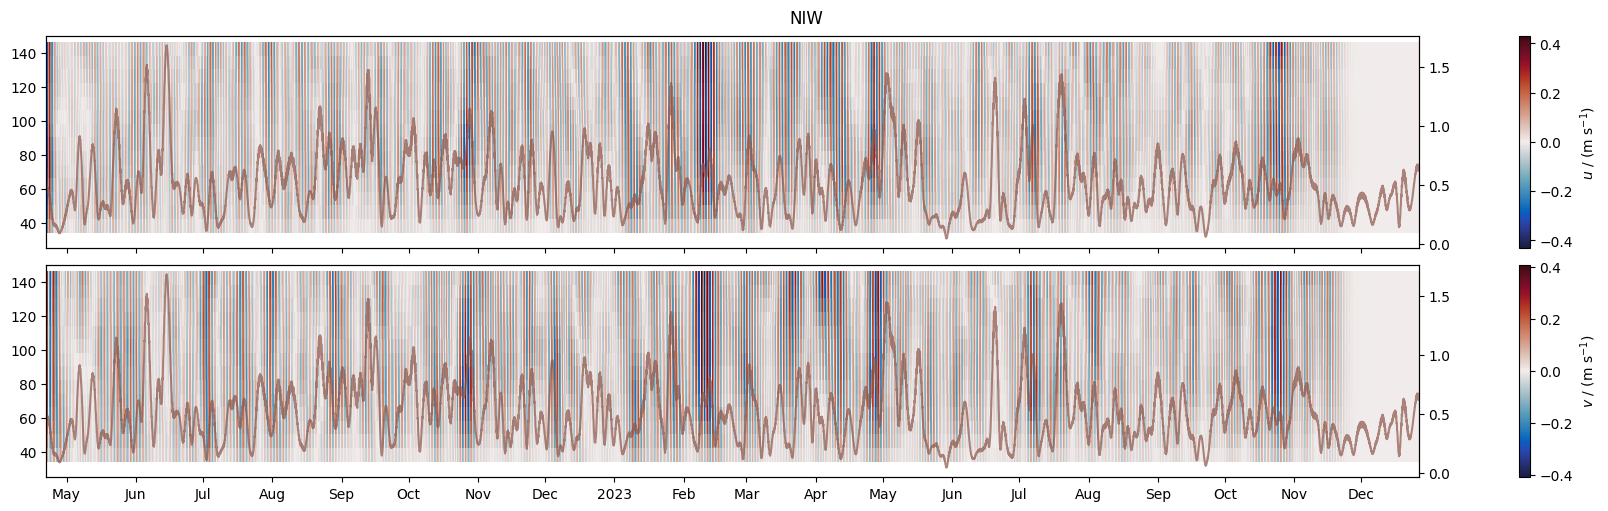

In [15]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, figsize=(16, 5), layout="constrained")

MAX_REASONABLE_VELOCITY = 4
max_plot_velocity = MAX_REASONABLE_VELOCITY
# max_plot_velocity= 2

im0 = ax[0].pcolormesh(
    u_f.index,
    u_f.columns,
    u_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_f.index,
    v_f.columns,
    v_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    axis.set_ylim(25, 150)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=32)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

fig.suptitle("NIW")

ax0 = ax[0].twinx()
ax0.plot(
    inertial_wind_at_C.index,
    inertial_wind_at_C.abs().rolling(window="1D").mean(),
    alpha=0.7,
    color="tab:brown",
)
ax1 = ax[1].twinx()
ax1.plot(
    inertial_wind_at_C.index,
    inertial_wind_at_C.abs().rolling(window="1D").mean(),
    alpha=0.7,
    color="tab:brown",
)

Text(0.5, 0.98, 'NIW')

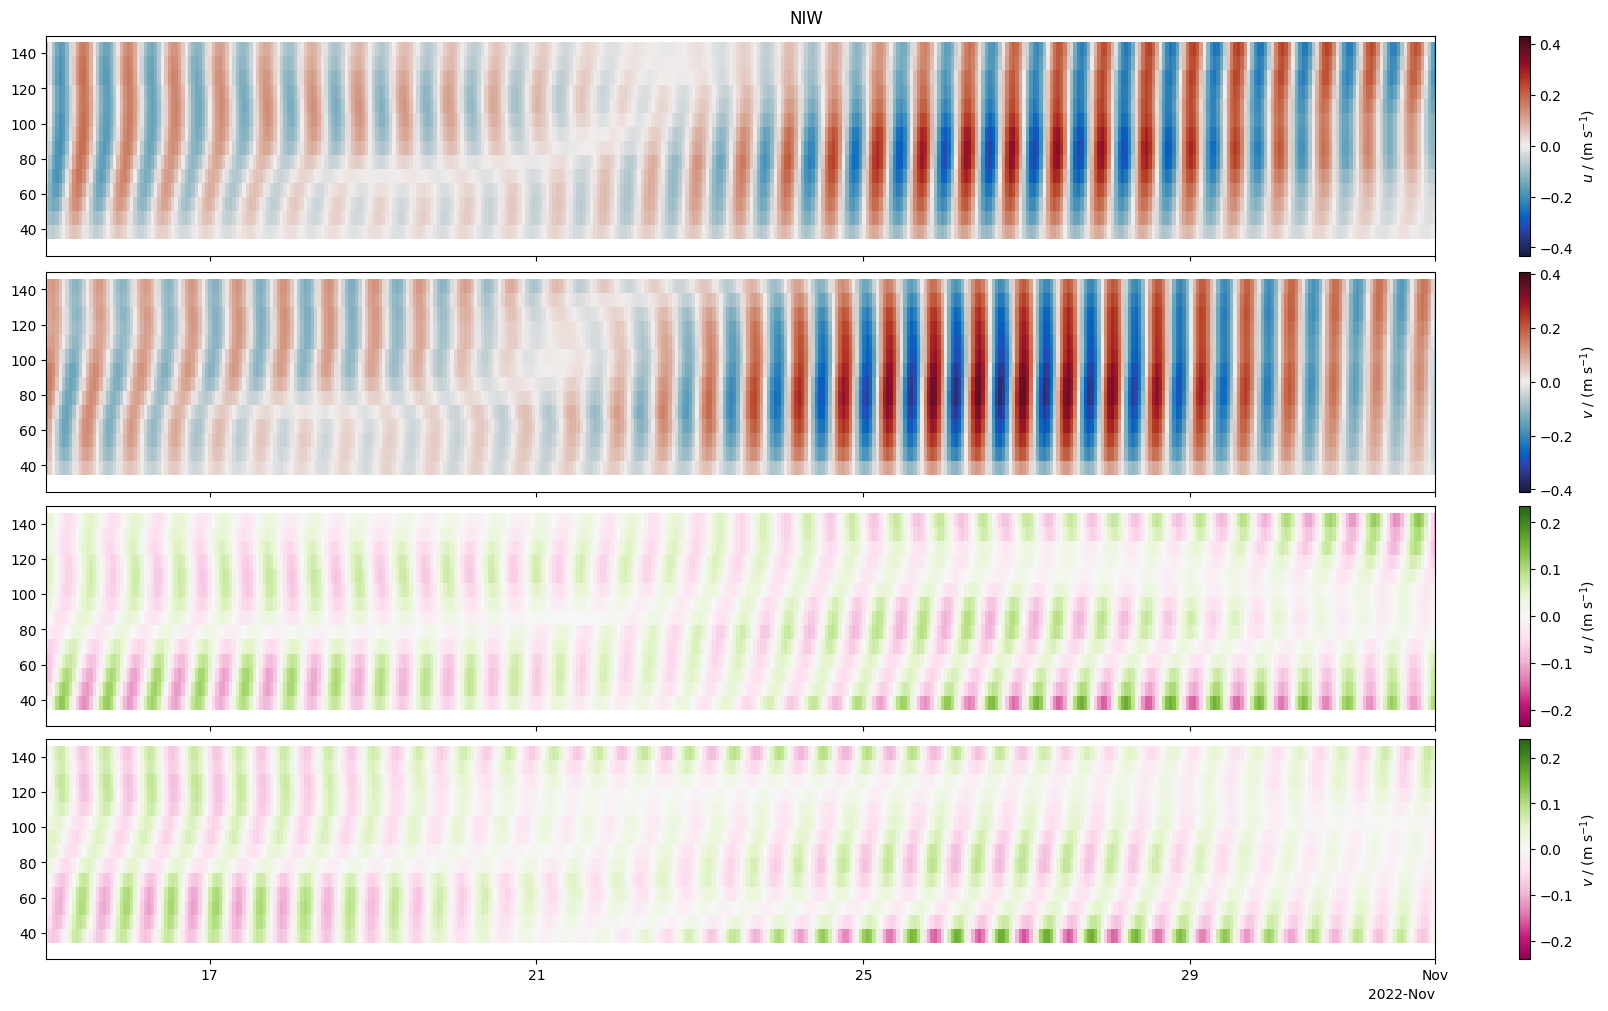

In [16]:
fig, ax = plt.subplots(nrows=4, sharex=True, sharey=True, figsize=(16, 10), layout="constrained")

im0 = ax[0].pcolormesh(
    u_f.index,
    u_f.columns,
    u_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_f.index,
    v_f.columns,
    v_f.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im2 = ax[2].pcolormesh(
    u_f.index,
    u_f.columns,
    u_f.sub(u_f.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap="PiYG",
)

im3 = ax[3].pcolormesh(
    v_f.index,
    v_f.columns,
    v_f.sub(v_f.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap="PiYG",
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

ubar = fig.colorbar(im2, ax=ax[2])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im3, ax=ax[3])
vbar.set_label("$v$ / (m s$^{-1}$)")

for axis in ax:
    axis.set_ylim(25, 150)
    # axis.set_xlim(mdates.datestr2num("2023-02"),mdates.datestr2num("2023-03"))
    axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

fig.suptitle("NIW")

# ax0 = ax[0].twinx()
# ax0.plot(inertial_wind_at_C.index, inertial_wind_at_C.abs().rolling(window="1D").mean(), alpha=0.7, color='tab:brown')
# ax1 = ax[1].twinx()
# ax1.plot(inertial_wind_at_C.index, inertial_wind_at_C.abs().rolling(window="1D").mean(), alpha=0.7, color='tab:brown')

# Filter to just tidal frequencies

In [97]:
# semidiurnal_tides = pinner2026_jpo_code.constants.get_tidal_frequencies_in_hours()
# 24 /np.array(list(semidiurnal_tides.values()))

In [98]:
def filter_to_semidiurnal(col, low_cut=1.06 * f, high_cut=2.05):

    low_cut_Hz = 1 / (24 / low_cut * 60 * 60)  # in Hz, default 1.91 cpd
    high_cut_Hz = 1 / (24 / high_cut * 60 * 60)  # in Hz, default: 2.05 cpd (approx K2)

    fs = 1 / (1 * 60 * 60)
    # low_cut = 1 / (12.5 * 60 * 60)
    # high_cut = 1 / (11.8 * 60 * 60)
    order = 40
    sos = signal.butter(
        N=order, Wn=(low_cut_Hz, high_cut_Hz), btype="bandpass", fs=fs, output="sos"
    )
    filtered = signal.sosfiltfilt(sos, col.to_numpy())
    return pd.Series(filtered, index=col.index)


u_semi = u.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_semidiurnal, axis="index")
v_semi = v.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_semidiurnal, axis="index")

(0.01, 1.0)

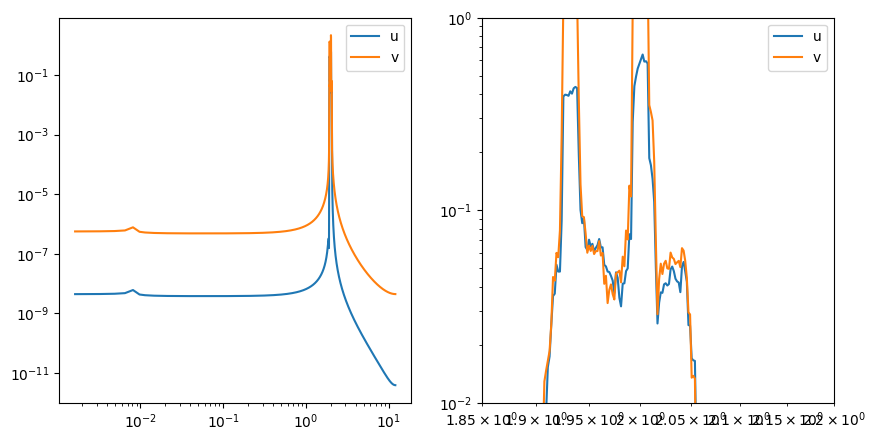

In [100]:
MEASUREMENT_PERIOD = 1 / 24
TIME_BANDWIDTH_PRODUCT = 5

mab = 54.23
u_freq, u_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    u_semi.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)
v_freq, v_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
    v_semi.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
)

fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
ax[0].loglog(u_freq, u_spectrum, label="u")
ax[0].loglog(v_freq, v_spectrum, label="v")
ax[0].legend()
# ax[0].set_xlim(1.7, 16)
# ax[0].set_ylim(9e-4, 0.2)

ax[1].loglog(u_freq, u_spectrum, label="u")
ax[1].loglog(v_freq, v_spectrum, label="v")
ax[1].legend()
ax[1].set_xlim(1.85, 2.2)
ax[1].set_ylim(1e-2, 1e0)

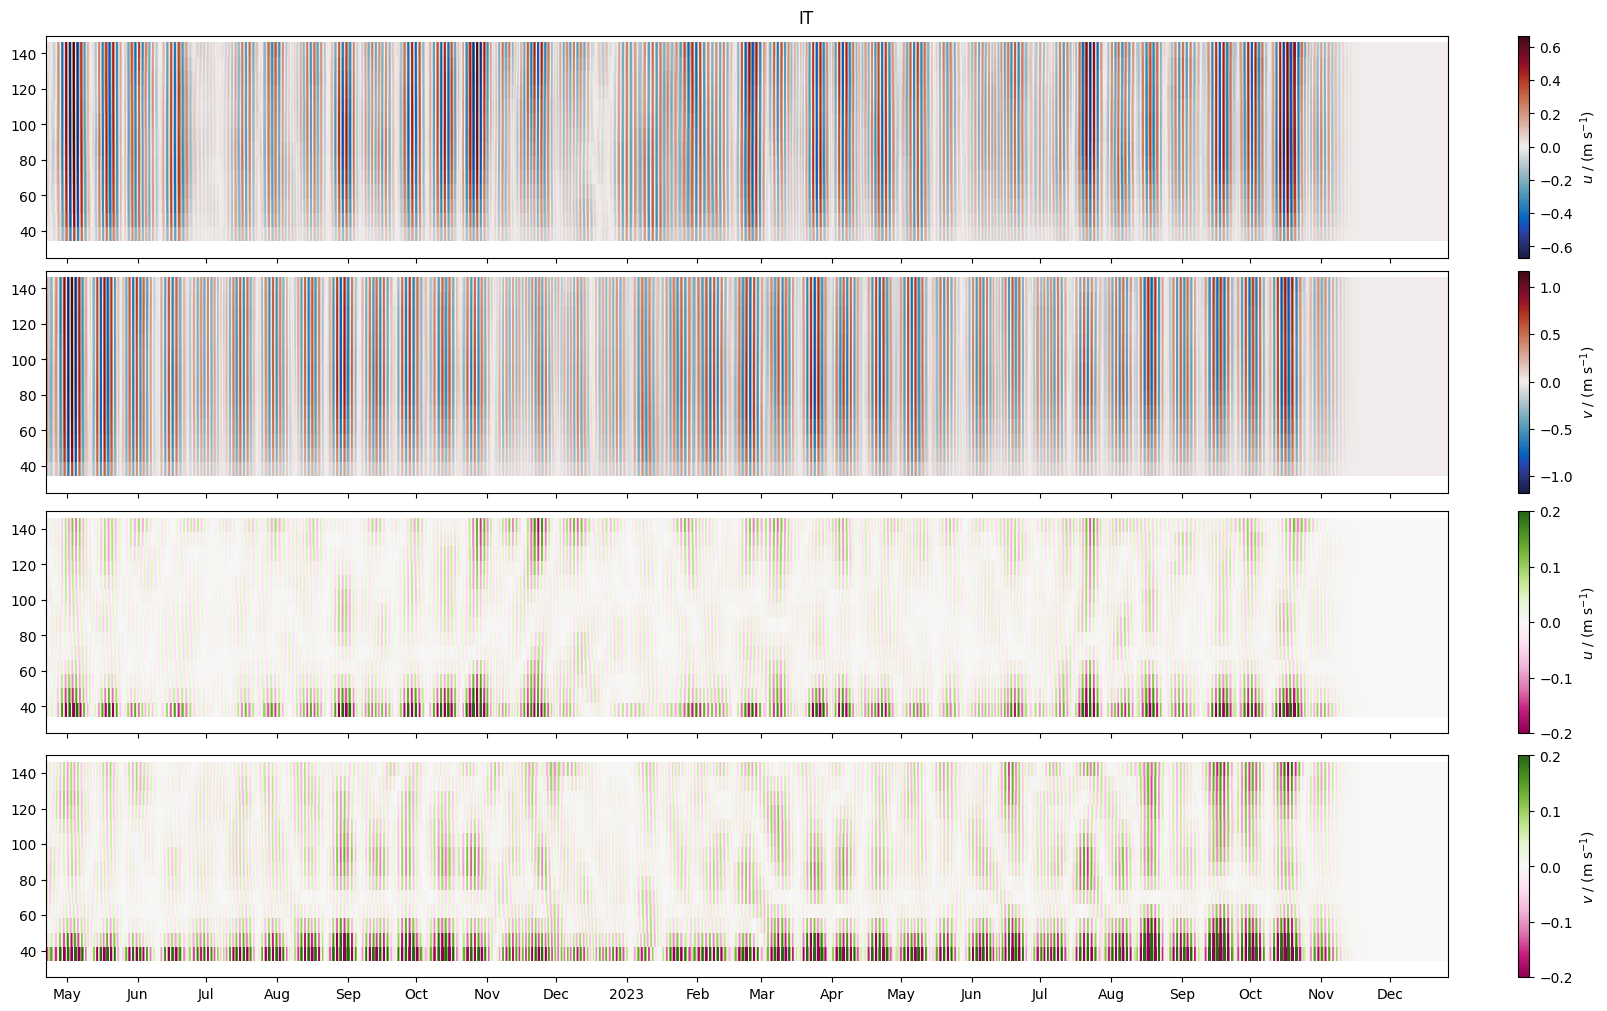

In [101]:
fig, ax = plt.subplots(nrows=4, sharex=True, sharey=True, figsize=(16, 10), layout="constrained")

im0 = ax[0].pcolormesh(
    u_semi.index,
    u_semi.columns,
    u_semi.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_semi.index,
    v_semi.columns,
    v_semi.to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im2 = ax[2].pcolormesh(
    u_semi.index,
    u_semi.columns,
    u_semi.sub(u_semi.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(halfrange=0.2),
    cmap="PiYG",
)

im3 = ax[3].pcolormesh(
    v_semi.index,
    v_semi.columns,
    v_semi.sub(v_semi.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(halfrange=0.2),
    cmap="PiYG",
)
ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

ubar = fig.colorbar(im2, ax=ax[2])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im3, ax=ax[3])
vbar.set_label("$v$ / (m s$^{-1}$)")

fig.suptitle("IT")

for axis in ax:
    axis.set_ylim(25, 150)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=32)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

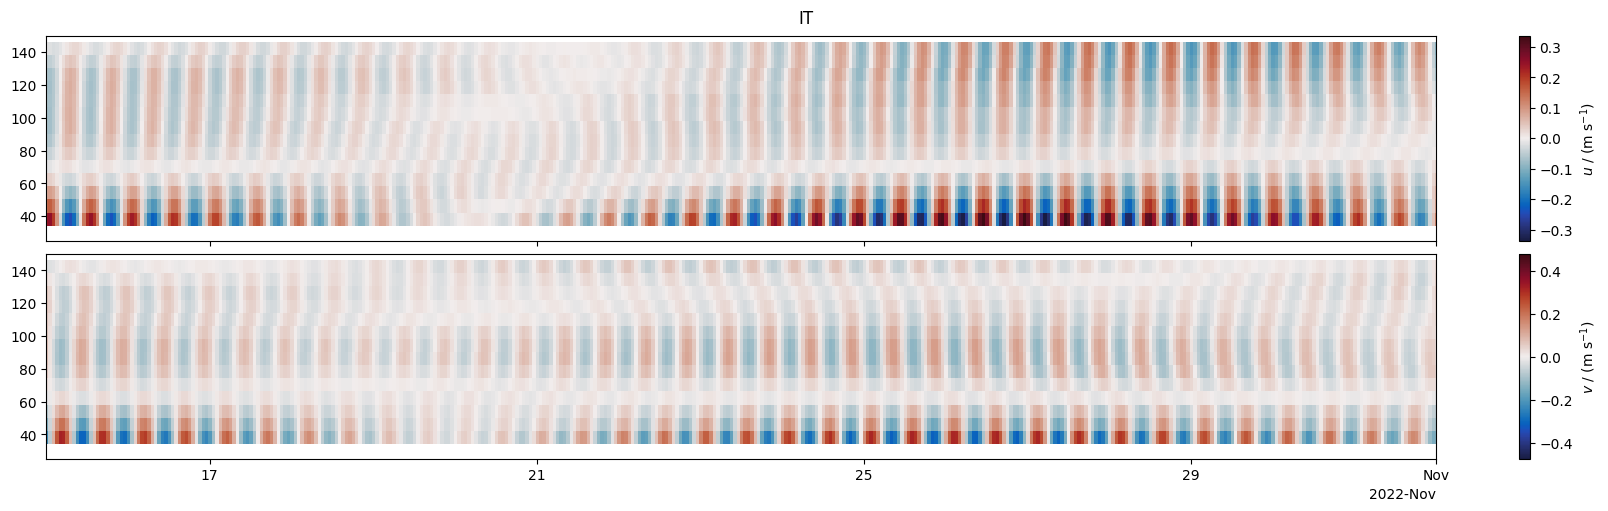

In [102]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, figsize=(16, 5), layout="constrained")

MAX_REASONABLE_VELOCITY = 4
max_plot_velocity = MAX_REASONABLE_VELOCITY
# max_plot_velocity= 2

im0 = ax[0].pcolormesh(
    u_semi.index,
    u_semi.columns,
    u_semi.sub(u_semi.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

im1 = ax[1].pcolormesh(
    v_semi.index,
    v_semi.columns,
    v_semi.sub(v_semi.mean(axis="columns"), axis="index").to_numpy().T,
    norm=mcolors.CenteredNorm(),
    cmap=cm.cm.balance,
)

ubar = fig.colorbar(im0, ax=ax[0])
ubar.set_label("$u$ / (m s$^{-1}$)")
vbar = fig.colorbar(im1, ax=ax[1])
vbar.set_label("$v$ / (m s$^{-1}$)")

fig.suptitle("IT")

for axis in ax:
    axis.set_ylim(25, 150)
    # axis.set_xlim(mdates.datestr2num("2023-02"),mdates.datestr2num("2023-03"))
    axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

# 2D Spectral Filtering

In [103]:
# def filter_to_fN(col):
#     fs = 1 / (1 * 60 * 60)
#     cut = 1 / (13.8 * 60 * 60)
#     order = 40
#     sos = signal.butter(N=order, Wn=cut, btype="highpass", fs=fs, output="sos")
#     filtered = signal.sosfiltfilt(sos, col.to_numpy())
#     return pd.Series(filtered, index=col.index)


# u_fN = u.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_fN, axis="index")
# v_fN = v.iloc[30:].interpolate(method="time", limit=3).apply(filter_to_fN, axis="index")

In [104]:
# MEASUREMENT_PERIOD = 1 / 24
# TIME_BANDWIDTH_PRODUCT = 5

# mab = 54.23
# u_freq, u_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
#     u_fN.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
# )
# v_freq, v_spectrum = pinner2026_jpo_code.spectra.total_multitaper(
#     v_fN.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
# )

# fig, ax = plt.subplots(ncols=2, figsize=(10, 5))
# ax[0].loglog(u_freq, u_spectrum, label="u")
# ax[0].loglog(v_freq, v_spectrum, label="v")
# ax[0].legend()
# ax[0].set_xlim(1.7, 16)
# ax[0].set_ylim(2e-4, 1)

# ax[1].loglog(u_freq, u_spectrum, label="u")
# ax[1].loglog(v_freq, v_spectrum, label="v")
# ax[1].legend()
# ax[1].set_xlim(1.85, 2.2)
# ax[1].set_ylim(1e-2, 1e0)

In [105]:
def decompose_CV_up_dn(CV, time, mab):
    """
    COPYRIGHT: SIMON REIFENBERG
    For a two-dimensional velocity field CV (time x depth), this function returns
    a decomposed velocity field based on 2D-fft filtering.

    Input must have dimensions N_TIME x N_DEPTH.

    The convention for the returned quadrant in terms of energy propagation is
    consistent with z decreasing with depth, with z=0 at the ocean surface.

    HOWEVER, this means that for an array where CV[:,0] is the bin closest to
    the surface and the associated depth array is positive-increasing, i.e.
    D[1] > D[0], the FFT returns the quadrants as for "physical z"
    DECREASING with depth. This is related to the array indexing.

    I am quite confused.

    Here is a scriptlet for simple sanity checks: <to be copied here>
    """

    NT, NZ = CV.shape

    F = np.fft.fftshift(np.fft.fft2(CV))

    freq = np.fft.fftshift(np.fft.fftfreq(NT))
    mm = np.fft.fftshift(np.fft.fftfreq(NZ))

    FREQ, MM = np.meshgrid(freq, mm, indexing="ij")

    Q1_pp = (FREQ > 0) & (MM > 0)  # downward
    Q2_pn = (FREQ > 0) & (MM < 0)  # upward
    Q3_nn = (FREQ < 0) & (MM < 0)  # downward
    Q4_np = (FREQ < 0) & (MM > 0)  # upward

    cv_1 = np.fft.ifft2(np.fft.ifftshift(Q1_pp * F))
    cv_2 = np.fft.ifft2(np.fft.ifftshift(Q2_pn * F))
    cv_3 = np.fft.ifft2(np.fft.ifftshift(Q3_nn * F))
    cv_4 = np.fft.ifft2(np.fft.ifftshift(Q4_np * F))

    return {
        "E_dn_CCW": pd.DataFrame(index=time, columns=mab, data=cv_1),
        "E_up_CCW": pd.DataFrame(index=time, columns=mab, data=cv_2),
        "E_dn_CW": pd.DataFrame(index=time, columns=mab, data=cv_3),
        "E_up_CW": pd.DataFrame(index=time, columns=mab, data=cv_4),
        "raw": {"E_dn_CCW": cv_1, "E_up_CCW": cv_2, "E_dn_CW": cv_3, "E_up_CW": cv_4},
    }

In [106]:
# complex velocity with CV[:,0] being the shallowest bin, i.e. highest mab
CV_f = u_f.dropna(axis="columns", how="all") + 1j * v_f.dropna(axis="columns", how="all")

# zero padding for sanity checks
# for mab in np.arange(start=142.23,stop=800,step = 8):
#     CV[mab] = 0

CV_f = CV_f.iloc[:, ::-1]
assert CV_f.columns[0] > CV_f.columns[1]  # the shallowest bin has to have the highest mab

# assumes the returned CV has the same direction of depth indices as the input CV
results_f = decompose_CV_up_dn(CV=CV_f, time=CV_f.index, mab=CV_f.columns)

In [120]:
import pickle

results_f_file = open(INTERIM_DATA_DIR / "NIW_filtered", "wb")
pickle.dump(results_f, results_f_file)
results_f_file.close()

Text(0.5, 0.98, 'NIW')

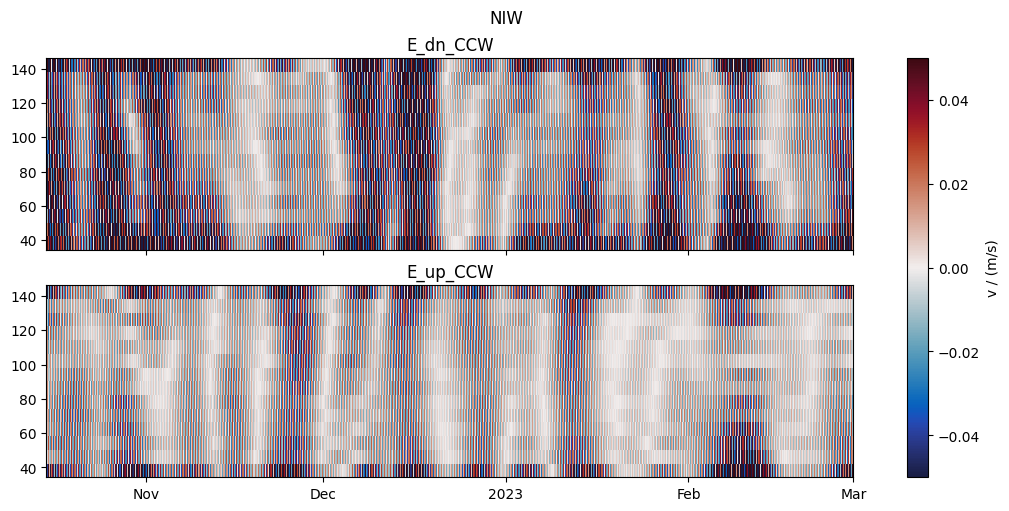

In [117]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, layout="constrained", figsize=(10, 5))
for i, (name, data) in enumerate(results_f.items()):
    if name == "raw":
        continue
    if "CCW" not in name:
        continue
    ax[i].set_title(name)
    im = ax[i].pcolormesh(
        data.index,
        data.columns,
        data.to_numpy().imag.T,  # v (east) velocity
        norm=mcolors.CenteredNorm(halfrange=0.05),
        cmap=cm.cm.balance,
    )

for axis in ax:
    # axis.set_ylim(30, 150)
    # axis.set_xlim(mdates.datestr2num("2023-02"),mdates.datestr2num("2023-03"))
    axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2023-03-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("v / (m/s)")
fig.suptitle("NIW")

# ax0 = ax[0].twinx()
# ax0.plot(
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
#     alpha=0.6,
#     color="tab:orange",
# )
# ax1 = ax[1].twinx()
# ax1.plot(
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
#     alpha=0.6,
#     color="tab:orange",
# )

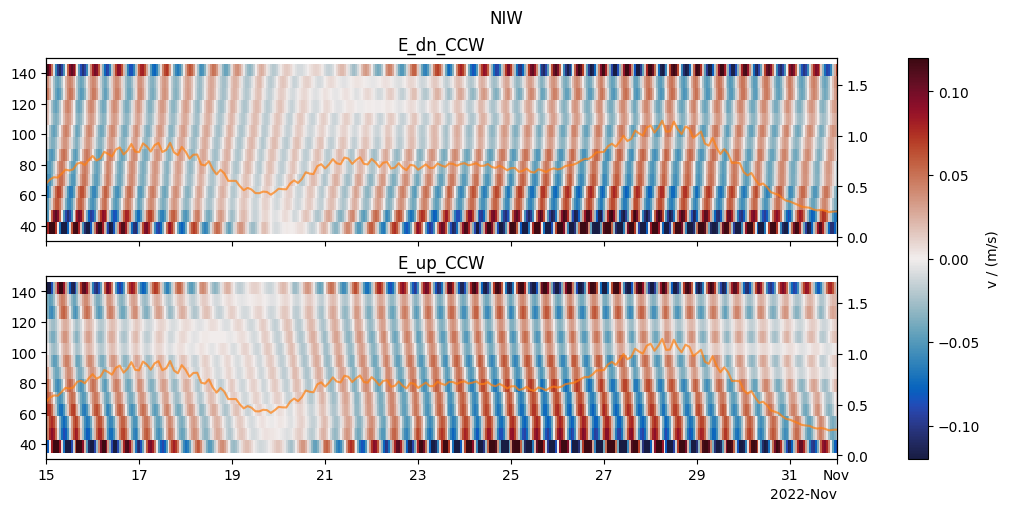

In [108]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, layout="constrained", figsize=(10, 5))
for i, (name, data) in enumerate(results_f.items()):
    if name == "raw":
        continue
    if "CCW" not in name:
        continue
    ax[i].set_title(name)
    im = ax[i].pcolormesh(
        data.index,
        data.columns,
        data.to_numpy().imag.T,  # v (east) velocity
        norm=mcolors.CenteredNorm(halfrange=0.12),
        cmap=cm.cm.balance,
    )

for axis in ax:
    axis.set_ylim(30, 150)
    axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=16)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

fig.suptitle("NIW")

ax0 = ax[0].twinx()
ax0.plot(
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
    alpha=0.7,
    color="tab:orange",
)
ax1 = ax[1].twinx()
ax1.plot(
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
    alpha=0.7,
    color="tab:orange",
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("v / (m/s)")

In [109]:
# results["E_dn_CCW"].loc[:, mab].apply(np.real).plot()
# results["E_dn_CCW"].loc[:, mab].apply(np.imag).plot()
# plt.gca().set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))

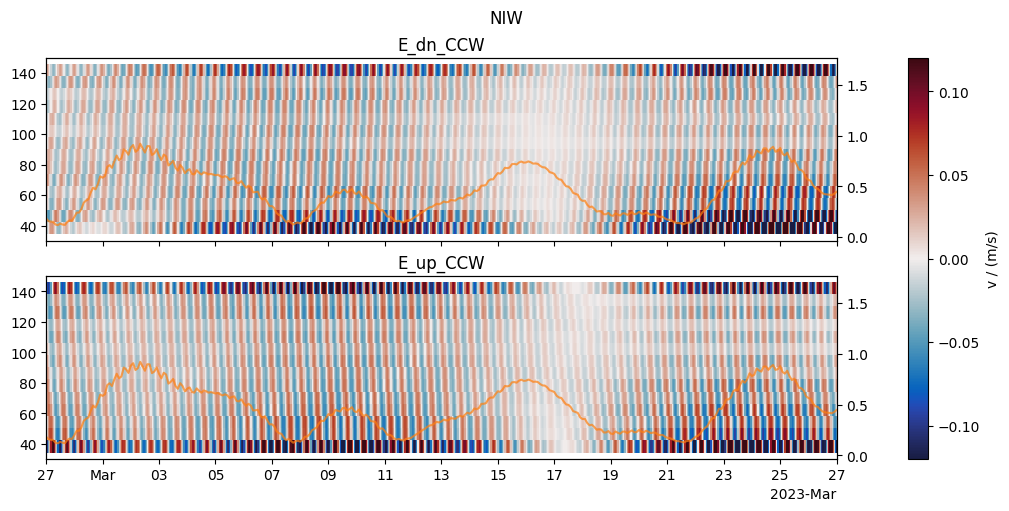

In [110]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, layout="constrained", figsize=(10, 5))
for i, (name, data) in enumerate(results_f.items()):
    if name == "raw":
        continue
    if "CCW" not in name:
        continue
    ax[i].set_title(name)
    im = ax[i].pcolormesh(
        data.index,
        data.columns,
        data.to_numpy().imag.T,  # v (east) velocity
        norm=mcolors.CenteredNorm(halfrange=0.12),
        cmap=cm.cm.balance,
    )

for axis in ax:
    axis.set_ylim(30, 150)
    axis.set_xlim(mdates.datestr2num("2023-02"), mdates.datestr2num("2023-03"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=16)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("v / (m/s)")

fig.suptitle("NIW")

ax0 = ax[0].twinx()
ax0.plot(
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
    alpha=0.7,
    color="tab:orange",
)
ax1 = ax[1].twinx()
ax1.plot(
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
    inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
    alpha=0.7,
    color="tab:orange",
)

In [111]:
# complex velocity with CV[:,0] being the shallowest bin, i.e. highest mab
CV_semi = u_semi.dropna(axis="columns", how="all") + 1j * v_semi.dropna(axis="columns", how="all")

# zero padding for sanity checks
# for mab in np.arange(start=142.23,stop=800,step = 8):
#     CV[mab] = 0

CV_semi = CV_semi.iloc[:, ::-1]
assert CV_semi.columns[0] > CV_semi.columns[1]  # the shallowest bin has to have the highest mab

# assumes the returned CV has the same direction of depth indices as the input CV
results_semi = decompose_CV_up_dn(CV=CV_semi, time=CV_semi.index, mab=CV_semi.columns)

In [121]:
results_semi_file = open(INTERIM_DATA_DIR / "IT_filtered", "wb")
pickle.dump(results_semi, results_semi_file)
results_semi_file.close()

Text(0.5, 0.98, 'IT')

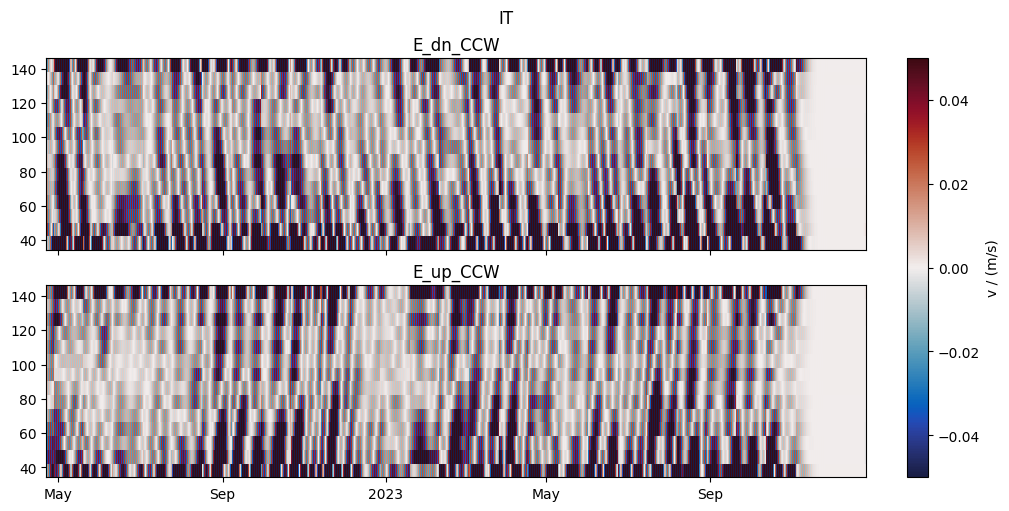

In [112]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, layout="constrained", figsize=(10, 5))
for i, (name, data) in enumerate(results_semi.items()):
    if name == "raw":
        continue
    if "CCW" not in name:
        continue
    ax[i].set_title(name)
    im = ax[i].pcolormesh(
        data.index,
        data.columns,
        data.to_numpy().imag.T,  # v (east) velocity
        norm=mcolors.CenteredNorm(halfrange=0.05),
        cmap=cm.cm.balance,
    )

for axis in ax:
    # axis.set_ylim(30, 150)
    # axis.set_xlim(mdates.datestr2num("2023-02"),mdates.datestr2num("2023-03"))
    # axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("v / (m/s)")
fig.suptitle("IT")

# ax0 = ax[0].twinx()
# ax0.plot(
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
#     alpha=0.6,
#     color="tab:orange",
# )
# ax1 = ax[1].twinx()
# ax1.plot(
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
#     alpha=0.6,
#     color="tab:orange",
# )

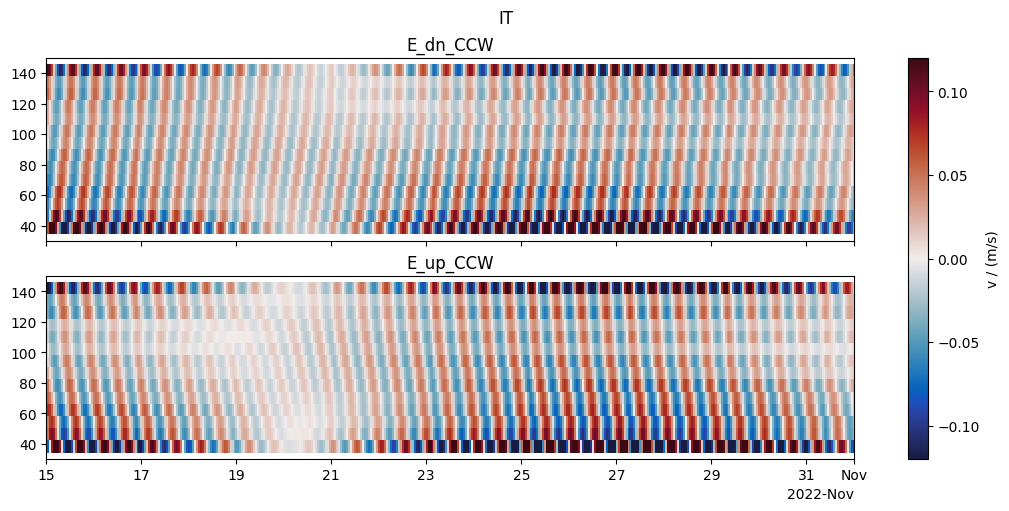

In [113]:
fig, ax = plt.subplots(nrows=2, sharex=True, sharey=True, layout="constrained", figsize=(10, 5))
for i, (name, data) in enumerate(results_semi.items()):
    if name == "raw":
        continue
    if "CCW" not in name:
        continue
    ax[i].set_title(name)
    im = ax[i].pcolormesh(
        data.index,
        data.columns,
        data.to_numpy().imag.T,  # v (east) velocity
        norm=mcolors.CenteredNorm(halfrange=0.12),
        cmap=cm.cm.balance,
    )

for axis in ax:
    axis.set_ylim(30, 150)
    axis.set_xlim(mdates.datestr2num("2022-10-15"), mdates.datestr2num("2022-11-01"))
    locator = mdates.AutoDateLocator(minticks=3, maxticks=16)
    formatter = mdates.ConciseDateFormatter(locator)
    axis.xaxis.set_major_locator(locator)
    axis.xaxis.set_major_formatter(formatter)

fig.suptitle("IT")

# ax0 = ax[0].twinx()
# ax0.plot(
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
#     alpha=0.7,
#     color="tab:orange",
# )
# ax1 = ax[1].twinx()
# ax1.plot(
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].index,
#     inertial_wind_at_C.loc[CV.index[0] : CV.index[-1]].abs().rolling(window="1D").mean(),
#     alpha=0.7,
#     color="tab:orange",
# )

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("v / (m/s)")

In [114]:
# MEASUREMENT_PERIOD = 1 / 24
# TIME_BANDWIDTH_PRODUCT = 5

# u_test = u.iloc[30:].interpolate(method="time", limit=3)
# v_test = v.iloc[30:].interpolate(method="time", limit=3)

# mab = 54.23
# rotary_spectra = pinner2026_jpo_code.spectra.rotary_multitaper(
#     u_test.loc[:, mab].to_numpy() + 1j * v_test.loc[:, mab].to_numpy(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
# )
# freq = rotary_spectra["freq"]
# CW_psd = rotary_spectra["neg_psd"]
# CCW_psd = rotary_spectra["pos_psd"]

# fig, axis = plt.subplots(ncols=1, figsize=(6, 5))
# ax = [axis]
# ax[0].loglog(freq, CW_psd, label="CW")
# ax[0].loglog(freq, CCW_psd, label="CCW")
# ax[0].legend()
# # ax[0].set_xlim(1.7, 16)
# ax[0].set_ylim(2e-4, 3)

In [115]:
# Sanity Test
# velocity = pd.read_csv(INTERIM_DATA_DIR / "velo_at_C.csv", parse_dates=True, index_col=0)
# for _i, col in enumerate(velocity.columns):
#     velocity[col] = velocity[col].str.replace("i", "j").apply(lambda x: complex(x))

# MEASUREMENT_PERIOD = 1 / 12
# TIME_BANDWIDTH_PRODUCT = 5

# mab = 54.23
# rotary_spectra = pinner2026_jpo_code.spectra.rotary_multitaper(
#     velocity.to_numpy().flatten(), dt=MEASUREMENT_PERIOD, P=TIME_BANDWIDTH_PRODUCT
# )
# freq = rotary_spectra["freq"]
# CW_psd = rotary_spectra["neg_psd"]
# CCW_psd = rotary_spectra["pos_psd"]

# fig, axis = plt.subplots(ncols=1, figsize=(6, 5))
# ax = [axis]
# ax[0].loglog(freq, CW_psd, label="CW")
# ax[0].loglog(freq, CCW_psd, label="CCW")
# ax[0].legend()
# ax[0].set_xlim(5e-1, 6)
# ax[0].set_ylim(6e-6, 1e-1)